# Лабораторная работа: полная конверсия ResNet-18 в SNN с частотным кодированием

## Цель работы

Самостоятельно реализовать конверсию предобученной `ResNet18` в спайковую сеть.

### План конверсии
1. Подготовка сети и калибровочного датасета.
2. Сбор статистик активаций на калибровочном датасете. Выбор активации отсечения.
3. Подготовка архитектуры. Слои BatchNorm сливаются с предшествующими свёртками
4. Замена нейронов. Слой ReLU заменяется на слой IF-нейронов с `reset-by-subtraction`;
5. Преобразование residual-блоков
6. Преобразование MaxPool

Этапы 1-4 реализованы в ноутбуках к лекции. Этапы 5-6 будут разобраны на лекции 6, но оставлены для самостоятельной реализации.

### Исследование
Исследовать качество полученной сети оценить для разных комбинаций параметров:
1. Длины временного окна $T=16,32,64,128,256$
2. Правила выбора активации отсечения: $max$, $p99$, $p99.9$

Для каждой комбинации оценить:
1. Качество классификацию ANN и SNN на тестовом фрагменте ImageNet. Не использовать для этого калибровочный датасет
2. Оценить переносимость признаков на любую выбранную задачу компьютерного зрения. Пример: сегментация, локализация.
3. Оценить число операций на одно изображение:
* MAC для ANN/SNN
* AC для ANN/SNN
* среднее число спайков на изображение
* среднее число спайков на один нейрон сети
* среднее число спайков на каждом слое сети

Ноутбук рассчитан на Google Colab с GPU. В режиме `FAST_MODE=True` используются небольшие подвыборки.

### Источники
* Презентации к лекциям 4,5
* Ноутбук с сетью VGG
* Статья по конверсии базовых свёрточных сетей
Rueckauer, B., Lungu, I. A., Hu, Y., Pfeiffer, M., & Liu, S. C. (2017). Conversion of continuous-valued deep networks to efficient event-driven networks for image classification. Frontiers in neuroscience, 11, 682.

* Статья по конверсии residual слоёв
Hu, Y., Tang, H., & Pan, G. (2021). Spiking deep residual networks. IEEE Transactions on Neural Networks and Learning Systems, 34(8), 5200-5205. URL:
https://arxiv.org/pdf/1805.01352


Можно использовать фреймворк SpikingJelly:
https://spikingjelly.readthedocs.io

## Теоретическая схема

Для ReLU-активации ANN $a_i^{(l)}\geq 0$ rate-конверсия использует число спайков IF-нейрона:

$$
\hat a_i^{(l)}(T)=\theta_l\frac{N_i^{(l)}(T)}{T},
$$

где $\theta_l$ — порог слоя, а $N_i^{(l)}(T)=\sum_{t=1}^{T}s_i^{(l)}[t]$.

Динамика IF-нейрона с мягким сбросом:

$$
u_i[t]=u_i[t-1]+I_i[t],
$$

$$
s_i[t]=H(u_i[t]-\theta_i),
$$

$$
u_i[t]\leftarrow u_i[t]-s_i[t]\theta_i.
$$

В отличие от `reset-to-zero`, вычитание порога сохраняет остаточный потенциал и уменьшает ошибку квантования частоты.

Выход IF-узла в программной модели записывается как $\theta s[t]$. На специализированном железе множитель $\theta$ можно заранее свернуть в веса следующего слоя, поэтому активный бинарный спайк инициирует прибавление предварительно масштабированного веса.

## 1. Установка и импорты

In [1]:
# В Colab основные пакеты уже установлены.
!pip -q install gdown pandas tqdm

In [2]:
import copy
import json
import math
import random
import time
import zipfile
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights
from torchvision.models.resnet import BasicBlock
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


## 2. Конфигурация эксперимента

In [3]:
FAST_MODE = True
T_CHECKPOINTS = [16, 32, 64, 128, 256]
MAXPOOL_WINDOW = 512  # Число последних тактов для оценки частоты.

# Число объектов для калибровки порогов и оценки классификации.
CALIBRATION_SAMPLES = 128 if FAST_MODE else 1024
CLASSIFICATION_SAMPLES = 128 if FAST_MODE else None
CLASSIFICATION_BATCH_SIZE = 8 if torch.cuda.is_available() else 2

# Высокий перцентиль устойчивее абсолютного максимума.
THRESHOLD_PERCENTILE = 0.999
ACTIVATION_SAMPLE_LIMIT = 100_000

DATA_DIR = Path('/content/data') if Path('/content').exists() else Path('./data')
RESULTS_DIR = Path('/content/results') if Path('/content').exists() else Path('./results')
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print('T checkpoints:', T_CHECKPOINTS)
print('FAST_MODE:', FAST_MODE)

T checkpoints: [16, 32, 64, 128, 256]
FAST_MODE: True


## 3. Фрагмент ImageNet: Imagenette

Ноутбук поддерживает фрагмент ImageNet в формате `ImageFolder`. По умолчанию используется ранее подготовленный ZIP-файл Imagenette на Google Drive.

Ожидаемая структура после распаковки:

```text
imagenette_subset/
  train/ или val/
    n01440764/
    n02102040/
    ...
```

Если файл уже находится на Google Drive, повторная загрузка не выполняется.

In [4]:
DOWNLOAD_URL = 'https://drive.google.com/uc?id=1JdnAT2kfg5CHby3DeL9q0fHkVdpluSrL'
DRIVE_ZIP = Path('/content/drive/MyDrive/imagenette_subset/imagenette_subset.zip')
LOCAL_ZIP = DATA_DIR / 'imagenette_subset.zip'
EXTRACT_DIR = DATA_DIR / 'imagenette_subset'

def prepare_imagenette_zip(download=True):
    """Монтирует Drive, при необходимости загружает ZIP и распаковывает его."""
    if Path('/content').exists():
        try:
            from google.colab import drive
            drive.mount('/content/drive', force_remount=False)
        except Exception as exc:
            print('Drive не смонтирован:', exc)

    zip_path = DRIVE_ZIP if DRIVE_ZIP.exists() else LOCAL_ZIP
    if not zip_path.exists() and download:
        import gdown
        LOCAL_ZIP.parent.mkdir(parents=True, exist_ok=True)
        gdown.download(url=DOWNLOAD_URL, output=str(LOCAL_ZIP), quiet=False)
        zip_path = LOCAL_ZIP

    if not zip_path.exists():
        raise FileNotFoundError(
            'ZIP не найден. Поместите его в DRIVE_ZIP или измените DOWNLOAD_URL.'
        )

    marker = EXTRACT_DIR / '.extracted'
    if not marker.exists():
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(EXTRACT_DIR)
        marker.touch()
    return EXTRACT_DIR

def find_imagefolder_root(root):
    """Ищет каталог val/train, содержащий папки классов ImageNet."""
    root = Path(root)
    candidates = []
    for path in [root, *root.rglob('*')]:
        if not path.is_dir():
            continue
        dirs = [p.name for p in path.iterdir() if p.is_dir()]
        if any(name.startswith('n') and len(name) == 9 for name in dirs):
            score = 2 if path.name == 'val' else 1 if path.name == 'train' else 0
            candidates.append((score, path))
    if not candidates:
        raise RuntimeError(f'Не найден ImageFolder внутри {root}')
    return sorted(candidates, key=lambda item: item[0], reverse=True)[0][1]

imagenette_root = find_imagefolder_root(prepare_imagenette_zip())
print('ImageFolder root:', imagenette_root)

ImageFolder root: data/imagenette_subset/imagenette_10k_subset


In [5]:
weights = ResNet18_Weights.DEFAULT
imagenet_transform = weights.transforms()

# Соответствие десяти WNID Imagenette исходным индексам ImageNet-1k.
IMAGENETTE_TO_IMAGENET = {
    'n01440764': 0,
    'n02102040': 217,
    'n02979186': 482,
    'n03000684': 491,
    'n03028079': 497,
    'n03394916': 566,
    'n03417042': 569,
    'n03425413': 571,
    'n03445777': 574,
    'n03888257': 701,
}

class RemapImageNetTargets(Dataset):
    def __init__(self, image_folder, mapping):
        self.base = image_folder
        self.mapping = mapping
        self.class_to_imagenet = {
            local_idx: mapping[class_name]
            for class_name, local_idx in image_folder.class_to_idx.items()
        }

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        image, local_target = self.base[index]
        return image, self.class_to_imagenet[local_target]

base_imagenette = datasets.ImageFolder(imagenette_root, transform=imagenet_transform)
missing = set(base_imagenette.classes) - set(IMAGENETTE_TO_IMAGENET)
if missing:
    raise ValueError(f'Неизвестные WNID: {sorted(missing)}')

imagenette = RemapImageNetTargets(base_imagenette, IMAGENETTE_TO_IMAGENET)

generator = torch.Generator().manual_seed(SEED)
all_indices = torch.randperm(len(imagenette), generator=generator).tolist()

calibration_indices = all_indices[:CALIBRATION_SAMPLES]
evaluation_indices = all_indices[CALIBRATION_SAMPLES:]

if CLASSIFICATION_SAMPLES is not None:
    evaluation_indices = evaluation_indices[:CLASSIFICATION_SAMPLES]

imagenette_eval = Subset(imagenette, evaluation_indices)

classification_loader = DataLoader(
    imagenette_eval,
    batch_size=CLASSIFICATION_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

calibration_loader = DataLoader(
    Subset(imagenette, calibration_indices),
    batch_size=CLASSIFICATION_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print('classes:', base_imagenette.classes)
print('evaluation images:', len(imagenette_eval))

classes: ['n01440764', 'n02102040', 'n02979186', 'n03028079', 'n03394916', 'n03425413', 'n03888257']
evaluation images: 128


## 4. Исходная ANN и базовое качество

In [6]:
@torch.inference_mode()
def classification_accuracy(model, loader, max_batches=None):
    model.eval()
    correct = 0
    total = 0
    for batch_idx, (images, targets) in enumerate(tqdm(loader, leave=False)):
        if max_batches is not None and batch_idx >= max_batches:
            break
        images = images.to(device)
        targets = targets.to(device)
        logits = model(images)
        correct += (logits.argmax(1) == targets).sum().item()
        total += targets.numel()
    return correct / max(total, 1)

ann = models.resnet18(weights=weights).eval().to(device)
ann_accuracy = classification_accuracy(ann, classification_loader)
print(f'ANN accuracy: {ann_accuracy:.4f}')

  0%|          | 0/16 [00:00<?, ?it/s]

ANN accuracy: 0.7500


## 5. Подсчёт MAC исходной ANN

Для свёртки без учёта bias:

$$
N_{MAC}=H_{out}W_{out}C_{out}\frac{C_{in}}{g}K_hK_w.
$$

Для полносвязного слоя:

$$
N_{MAC}=N_{in}N_{out}.
$$

После BatchNorm folding операции BatchNorm отдельно не учитываются.

In [7]:
def dense_ops(module, x, y):
    batch = x.shape[0]
    if isinstance(module, nn.Conv2d):
        out_h, out_w = y.shape[-2:]
        kernel_h, kernel_w = module.kernel_size
        per_sample = (
            out_h * out_w * module.out_channels
            * (module.in_channels // module.groups)
            * kernel_h * kernel_w
        )
    elif isinstance(module, nn.Linear):
        per_sample = module.in_features * module.out_features
    else:
        return 0
    return int(batch * per_sample)

class ANNMacCounter:
    def __init__(self, model):
        self.total = 0
        self.ac = 0
        self.handles = []
        for module in model.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                self.handles.append(module.register_forward_hook(self._hook))

            elif isinstance(module, BasicBlock):
                self.handles.append(module.register_forward_hook(self._residual_hook))

    def _residual_hook(self, module, inputs, output):
        self.ac += output.numel()

    def _hook(self, module, inputs, output):
        self.total += dense_ops(module, inputs[0], output)

    def close(self):
        for handle in self.handles:
            handle.remove()

with torch.inference_mode():
    sample_images, _ = next(iter(classification_loader))
    sample_images = sample_images[:1].to(device)
    counter = ANNMacCounter(ann)
    _ = ann(sample_images)
    ann_macs_per_image = counter.total
    ann_residual_ac_per_image = counter.ac
    counter.close()

print(f'ANN MAC/image: {ann_macs_per_image:,}')
# Только сложения residual-ветвей; pooling и bias отдельно не учитываются.
print(f'ANN residual AC/image: {ann_residual_ac_per_image:,}')


ANN MAC/image: 1,814,073,344
ANN residual AC/image: 752,640


## 6. BatchNorm folding

Для свёртки $y=Wx+b$ и BatchNorm в режиме inference:

$$
\operatorname{BN}(y)=\gamma\frac{y-\mu}{\sqrt{\sigma^2+\varepsilon}}+\beta.
$$

Эквивалентные параметры:

$$
W'=\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}}W,
$$

$$
b'=\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}}(b-\mu)+\beta.
$$

После преобразования BatchNorm заменяется на `Identity`.

In [8]:
from torch.nn.utils import fuse_conv_bn_eval


def fold_resnet18_bn(model):
    # Сохраняем исходную ANN для сравнения.
    folded = copy.deepcopy(model).eval()

    # Входная свёртка.
    folded.conv1 = fuse_conv_bn_eval(folded.conv1, folded.bn1)
    folded.bn1 = nn.Identity()

    # Свёртки внутри residual-блоков.
    for layer in (folded.layer1, folded.layer2,
                  folded.layer3, folded.layer4):
        for block in layer:
            block.conv1 = fuse_conv_bn_eval(block.conv1, block.bn1)
            block.bn1 = nn.Identity()

            block.conv2 = fuse_conv_bn_eval(block.conv2, block.bn2)
            block.bn2 = nn.Identity()

            # Ветка изменения размера и числа каналов.
            if block.downsample is not None:
                block.downsample = nn.Sequential(
                    fuse_conv_bn_eval(
                        block.downsample[0],
                        block.downsample[1],
                    )
                )

    return folded


# Рабочая модель для калибровки и конверсии в SNN.
ann_folded = fold_resnet18_bn(ann)

In [9]:
# Проверка эквивалентности до и после folding на CPU в float64.
ann_check = copy.deepcopy(ann).cpu().double().eval()
folded_check = fold_resnet18_bn(ann_check)

assert not any(
    isinstance(module, nn.BatchNorm2d)
    for module in folded_check.modules()
)

with torch.inference_mode():
    images, _ = next(iter(classification_loader))
    images = images[:1].cpu().double()

    original_logits = ann_check(images)
    folded_logits = folded_check(images)

    max_error = (original_logits - folded_logits).abs().max().item()
    print(f'Максимальная разница: {max_error:.6g}')

    torch.testing.assert_close(
        folded_logits,
        original_logits,
        rtol=1e-7,
        atol=1e-8,
    )

print('Проверка пройдена: выходы совпадают в пределах допуска.')

del ann_check, folded_check

Максимальная разница: 1.26565e-14
Проверка пройдена: выходы совпадают в пределах допуска.


## 7. Калибровка порогов IF-нейронов

Порог слоя оценивается по распределению положительных ReLU-активаций:

$$
\theta_l=Q_p\left(a^{(l)}\right),
$$

где $Q_p$ — перцентиль, например $p=0.999$.

Абсолютный максимум чувствителен к единичным выбросам. Слишком низкий порог приводит к насыщению $N(T)=T$, слишком высокий — к малому числу спайков и большой ошибке квантования.

In [10]:
def calibrate_thresholds(percentile):
    activations = defaultdict(list)
    calls = defaultdict(int)
    handles = []

    # Сколько значений сохранять с каждого батча для одного ReLU.
    sample_size = max(1, ACTIVATION_SAMPLE_LIMIT // len(calibration_loader))

    def make_hook(name):
        def hook(module, inputs, output):
            calls[name] += 1
            key = name if name == 'relu' else f'{name}{calls[name]}'

            values = output.detach().flatten()
            values = values[values > 0]

            if percentile == 1:
                values = values.max().reshape(1) if values.numel() else values
            elif values.numel() > sample_size:
                indices = torch.randint(values.numel(), (sample_size,),
                                        device=values.device)
                values = values[indices]

            activations[key].append(values.cpu())
        return hook

    for name, module in ann_folded.named_modules():
        if isinstance(module, nn.ReLU):
            handles.append(module.register_forward_hook(make_hook(name)))

    ann_folded.eval()
    try:
        with torch.inference_mode():
            for images, _ in tqdm(calibration_loader):
                calls.clear()
                ann_folded(images.to(device))
    finally:
        for handle in handles:
            handle.remove()

    thresholds = {}
    for name, parts in activations.items():
        values = torch.cat(parts)
        threshold = (
            torch.quantile(values, percentile).item()
            if values.numel() else 0.0
        )
        thresholds[name] = max(threshold, 1e-6)

    return thresholds

## 8. IF-нейрон с soft reset

`IFNode` хранит мембранный потенциал между временными шагами, но состояние обязательно обнуляется перед новым batch. Поле `spike_count` нужно только для диагностики и не участвует в вычислении выхода.

In [11]:
class IFNode(nn.Module):
    def __init__(self, threshold, name):
        super().__init__()
        self.register_buffer('threshold', torch.tensor(float(threshold)))
        self.name = name
        self.membrane = None
        self.spike_count = 0

    def reset_state(self):
        self.membrane = None
        self.spike_count = 0

    def forward(self, current):
        if self.membrane is None or self.membrane.shape != current.shape:
            self.membrane = torch.zeros_like(current)
        self.membrane = self.membrane + current
        spike = self.membrane.ge(self.threshold).to(current.dtype)
        self.membrane = self.membrane - spike * self.threshold
        self.spike_count += int(spike.count_nonzero().item())
        return spike * self.threshold

## 9. Конверсия MaxPool блока
Блок MaxPool должен динамически оценить частоту потока спайков $\hat{r_i}$ и выбрать победителя за подвижный временной интервал.


Реализация считает спайки за последние `MAXPOOL_WINDOW` тактов, включая текущий. Более старые спайки исключаются. В начале используются доступные такты; перед новым батчем история сбрасывается. Значение 32 — начальный выбор параметра, не требование задания.


In [12]:
from collections import deque


class SpikingMaxPool2d(nn.Module):
    def __init__(self, kernel_size=3, stride=2, padding=1, window=32):
        super().__init__()
        if window < 1:
            raise ValueError('window должен быть положительным')
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        self.window = window
        self.history = deque()
        self.counts = None

    def reset_state(self):
        self.history.clear()
        self.counts = None

    def forward(self, x):
        if self.counts is None:
            self.counts = torch.zeros_like(x)

        # Оставляем спайки только последних window тактов, включая текущий.
        if len(self.history) == self.window:
            self.counts -= self.history.popleft().to(x.dtype)
        spikes = x > 0
        self.history.append(spikes)
        self.counts += spikes.to(x.dtype)

        # Деление на длину окна не меняет положение максимума.
        _, indices = F.max_pool2d(
            self.counts,
            kernel_size=self.kernel_size,
            stride=self.stride,
            padding=self.padding,
            return_indices=True,
        )
        return x.flatten(2).gather(
            2, indices.flatten(2)
        ).reshape_as(indices)


## 10. Конверсия residual-блока

ANN-блок:

$$
y=\operatorname{ReLU}\left(F(x)+x\right),
$$

В SNN основная и residual-ветви формируют ток одного выходного IF-нейрона:

$$
I_y[t]=F_s(x[t])+x[t],
$$

$$
y[t]=\operatorname{IF}_{\theta_2}(I_y[t]).
$$


In [13]:
class SNNOperationCounter:
    """Оценка MAC и AC во время фактического forward.

    Ненулевой элемент входного spike tensor считается активным событием.
    Для Conv/Linear AC оцениваются как dense_ops * input_density.
    """
    def __init__(self):
        self.mac = 0.0
        self.ac = 0.0
        self.residual_ac = 0.0
        self.enabled = False
        self.analog_modules = set()
        self.handles = []

    def attach(self, model, analog_modules=()):
        self.analog_modules = {id(module) for module in analog_modules}
        for module in model.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                self.handles.append(module.register_forward_hook(self._hook))

    def _hook(self, module, inputs, output):
        if not self.enabled:
            return
        x = inputs[0]
        dense = dense_ops(module, x, output)
        if id(module) in self.analog_modules:
            self.mac += dense
        else:
            density = float(x.count_nonzero().item()) / max(x.numel(), 1)
            self.ac += dense * density

    def add_residual(self, main, identity):
        if self.enabled:
            self.residual_ac += main.count_nonzero().item() + identity.count_nonzero().item()

    def reset(self):
        self.mac = self.ac = self.residual_ac = 0.0

    def snapshot(self):
        return {
            'mac': self.mac,
            'synaptic_ac': self.ac,
            'residual_ac': self.residual_ac,
            'total_ac': self.ac + self.residual_ac,
        }

    def close(self):
        for handle in self.handles:
            handle.remove()

class SpikingBasicBlock(nn.Module):
    expansion = 1

    def __init__(self, ann_block, threshold1, threshold2, name, op_counter=None):
        super().__init__()
        self.conv1 = copy.deepcopy(ann_block.conv1)
        self.conv2 = copy.deepcopy(ann_block.conv2)
        self.downsample = copy.deepcopy(ann_block.downsample)

        self.if1 = IFNode(threshold1, f'{name}.relu1')
        self.if2 = IFNode(threshold2, f'{name}.relu2')
        self.op_counter = op_counter

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.if1(self.conv1(x))
        out = self.conv2(out)
        if self.op_counter is not None:
            self.op_counter.add_residual(out, identity)
        out = self.if2(out + identity)
        return out

## 11. Полная SNN ResNet-18

Первый слой по умолчанию получает аналоговое нормализованное изображение. Его свёртка вычисляется один раз, а постоянный ток подаётся на первый IF-нейрон в каждом такте. Это стандартный практический компромисс: скрытые представления являются спайковыми, а дорогая первая свёртка не повторяется $T$ раз.

Опциональный режим `signed_poisson` генерирует знаковые входные события для нормализованных пикселей, но обычно имеет большую дисперсию и работает медленнее.

In [14]:
class SpikingResNet18(nn.Module):
    def __init__(self, ann, thresholds):
        super().__init__()
        self.op_counter = SNNOperationCounter()

        self.conv1 = copy.deepcopy(ann.conv1)
        self.if1 = IFNode(thresholds['relu'], 'relu')
        self.maxpool = SpikingMaxPool2d(window=MAXPOOL_WINDOW)

        for layer_name in ('layer1', 'layer2', 'layer3', 'layer4'):
            blocks = []
            for i, block in enumerate(getattr(ann, layer_name)):
                name = f'{layer_name}.{i}'
                blocks.append(SpikingBasicBlock(
                    block,
                    thresholds[f'{name}.relu1'],
                    thresholds[f'{name}.relu2'],
                    name,
                    self.op_counter,
                ))
            setattr(self, layer_name, nn.Sequential(*blocks))

        self.avgpool = copy.deepcopy(ann.avgpool)
        self.fc = copy.deepcopy(ann.fc)

        # Вход и результат усреднения перед fc — аналоговые значения.
        self.op_counter.attach(self, analog_modules=(self.conv1, self.fc))

    def reset_state(self):
        for module in self.modules():
            if isinstance(module, (IFNode, SpikingMaxPool2d)):
                module.reset_state()
        self.op_counter.reset()

    @torch.inference_mode()
    def forward_checkpoints(self, images, checkpoints):
        self.reset_state()
        self.op_counter.enabled = True
        results = {}
        logits_sum = 0

        # Первую свёртку считаем один раз на весь временной интервал.
        current = self.conv1(images)

        for t in range(1, max(checkpoints) + 1):
            x = self.maxpool(self.if1(current))
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)
            x = self.layer4(x)

            logits = self.fc(self.avgpool(x).flatten(1))
            logits_sum = logits_sum + logits

            if t in checkpoints:
                results[t] = {
                    'logits': logits_sum / t,
                    'spikes': sum(
                        module.spike_count
                        for module in self.modules()
                        if isinstance(module, IFNode)
                    ),
                    'spikes_by_layer': {
                        m.name: m.spike_count for m in self.modules()
                        if isinstance(m, IFNode)
                    },
                    'neurons_by_layer': {
                        m.name: m.membrane[0].numel() for m in self.modules()
                        if isinstance(m, IFNode)
                    },
                    'ops': self.op_counter.snapshot(),
                }

        self.op_counter.enabled = False
        return results

    def forward(self, images, T=32):
        return self.forward_checkpoints(images, [T])[T]['logits']


## 12. Классификация Imagenette при разных $T$

In [15]:
@torch.inference_mode()
def evaluate_snn_checkpoints(model, loader, checkpoints):
    totals = {
        t: {
            'correct': 0,
            'samples': 0,
            'spikes': 0,
            'spikes_by_layer': defaultdict(int),
            'mac': 0.0,
            'synaptic_ac': 0.0,
            'residual_ac': 0.0,
        }
        for t in checkpoints
    }

    for images, targets in tqdm(loader, desc='SNN classification'):
        images = images.to(device)
        targets = targets.to(device)
        batch_outputs = model.forward_checkpoints(images, checkpoints)

        for t, output in batch_outputs.items():
            row = totals[t]
            row['correct'] += (output['logits'].argmax(1) == targets).sum().item()
            row['samples'] += targets.numel()
            row['spikes'] += output['spikes']
            for name, count in output['spikes_by_layer'].items():
                row['spikes_by_layer'][name] += count
            row['neurons_by_layer'] = output['neurons_by_layer']
            row['mac'] += output['ops']['mac']
            row['synaptic_ac'] += output['ops']['synaptic_ac']
            row['residual_ac'] += output['ops']['residual_ac']

    rows = []
    for t in checkpoints:
        row = totals[t]
        n = max(row['samples'], 1)
        total_ac = row['synaptic_ac'] + row['residual_ac']
        rows.append({
            'T': t,
            'accuracy': row['correct'] / n,
            'accuracy_drop': ann_accuracy - row['correct'] / n,
            'spikes_per_image': row['spikes'] / n,
            'spikes_per_neuron': row['spikes'] / (n * sum(row['neurons_by_layer'].values())),
            'ANN_MAC_per_image': ann_macs_per_image,
            'ANN_residual_AC_per_image': ann_residual_ac_per_image,
            'MAC_per_image': row['mac'] / n,
            'synaptic_AC_per_image': row['synaptic_ac'] / n,
            'residual_AC_per_image': row['residual_ac'] / n,
            'total_AC_per_image': total_ac / n,
            'AC_to_ANN_MAC': (total_ac / n) / ann_macs_per_image,
        })
        for name, count in row['spikes_by_layer'].items():
            rows[-1][f'{name}_spikes_per_image'] = count / n
            rows[-1][f'{name}_spikes_per_neuron'] = count / (n * row['neurons_by_layer'][name])
    return pd.DataFrame(rows)

tables = []

for p in (0.99, 0.999, 1.0):
    print(f'Калибровка и оценка для p={p}')
    thresholds = calibrate_thresholds(p)
    snn = SpikingResNet18(ann_folded, thresholds).to(device).eval()

    assert not any(isinstance(m, nn.BatchNorm2d) for m in snn.modules())
    assert sum(isinstance(m, IFNode) for m in snn.modules()) == 17

    table = evaluate_snn_checkpoints(
        snn, classification_loader, T_CHECKPOINTS
    )
    table['p'] = p
    tables.append(table)
    table.to_csv(RESULTS_DIR / f'classification_p{p}.csv', index=False)
    snn.op_counter.close()

all_results = pd.concat(tables, ignore_index=True)
all_results.to_csv(RESULTS_DIR / 'all_thresholds_results.csv', index=False)
all_results


Калибровка и оценка для p=0.99


  0%|          | 0/16 [00:00<?, ?it/s]

SNN classification:   0%|          | 0/16 [00:00<?, ?it/s]

Калибровка и оценка для p=0.999


  0%|          | 0/16 [00:00<?, ?it/s]

SNN classification:   0%|          | 0/16 [00:00<?, ?it/s]

Калибровка и оценка для p=1.0


  0%|          | 0/16 [00:00<?, ?it/s]

SNN classification:   0%|          | 0/16 [00:00<?, ?it/s]

,T,accuracy,accuracy_drop,spikes_per_image,spikes_per_neuron,ANN_MAC_per_image,ANN_residual_AC_per_image,MAC_per_image,synaptic_AC_per_image,residual_AC_per_image,...,layer3.1.relu2_spikes_per_neuron,layer4.0.relu1_spikes_per_image,layer4.0.relu1_spikes_per_neuron,layer4.0.relu2_spikes_per_image,layer4.0.relu2_spikes_per_neuron,layer4.1.relu1_spikes_per_image,layer4.1.relu1_spikes_per_neuron,layer4.1.relu2_spikes_per_image,layer4.1.relu2_spikes_per_neuron,p
0,16,0.000000,0.750000,5.977691e+06,2.589880,1814073344,752640,126205952.0,3.120490e+09,1.710435e+07,...,1.114484,11029.781250,0.439644,12153.796875,0.484447,15528.406250,0.618958,28759.343750,1.146339,0.990
1,32,0.164062,0.585938,1.219597e+07,5.283998,1814073344,752640,134397952.0,6.328128e+09,3.441294e+07,...,2.599955,23516.429688,0.937358,26277.125000,1.047398,31377.718750,1.250706,63402.132812,2.527190,0.990
2,64,0.312500,0.437500,2.465448e+07,10.681740,1814073344,752640,150781952.0,1.272374e+10,6.889447e+07,...,5.686159,48482.585938,1.932501,55252.242188,2.202337,65511.328125,2.611261,142115.648438,5.664686,0.990
3,128,0.367188,0.382812,4.961223e+07,21.494871,1814073344,752640,183549952.0,2.547439e+10,1.375503e+08,...,11.976902,99535.640625,3.967460,115269.382812,4.594602,134897.312500,5.376966,307798.382812,12.268749,0.990
4,256,0.437500,0.312500,9.970466e+07,43.197795,1814073344,752640,249085952.0,5.096381e+10,2.743362e+08,...,24.691337,204535.929688,8.152740,238604.156250,9.510689,273617.367188,10.906304,646816.656250,25.781914,0.990
5,16,0.007812,0.742188,3.945030e+06,1.709214,1814073344,752640,126205952.0,2.151827e+09,1.636467e+07,...,0.646927,6601.906250,0.263150,7178.554688,0.286135,11676.460938,0.465420,22778.664062,0.907951,0.999
6,32,0.132812,0.617188,8.126068e+06,3.520680,1814073344,752640,134397952.0,4.392303e+09,3.295744e+07,...,1.562197,14601.406250,0.582008,16616.882812,0.662344,21903.523438,0.873068,45970.382812,1.832365,0.999
7,64,0.343750,0.406250,1.647575e+07,7.138244,1814073344,752640,150781952.0,8.828111e+09,6.603406e+07,...,3.500478,30480.359375,1.214938,35970.367188,1.433768,43376.773438,1.728985,98093.054688,3.909959,0.999
8,128,0.398438,0.351562,3.308230e+07,14.333157,1814073344,752640,183549952.0,1.756384e+10,1.318984e+08,...,7.468760,62783.460938,2.502530,75743.820312,3.019125,87196.023438,3.475607,209102.812500,8.334774,0.999
9,256,0.484375,0.265625,6.614407e+07,28.657415,1814073344,752640,249085952.0,3.479636e+10,2.630777e+08,...,15.480875,129688.960938,5.169362,157956.531250,6.296099,175020.734375,6.976273,439183.554688,17.505722,0.999


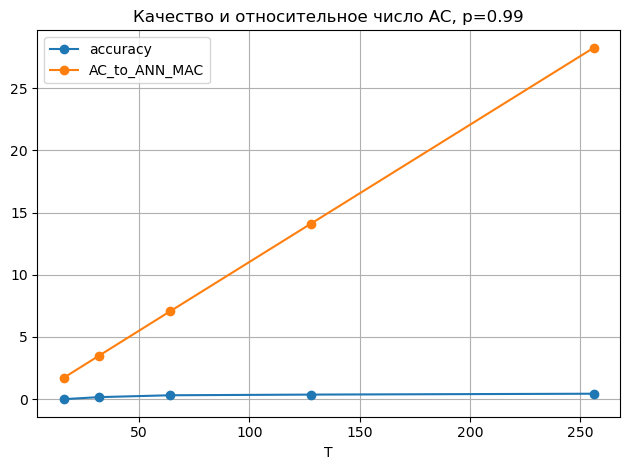

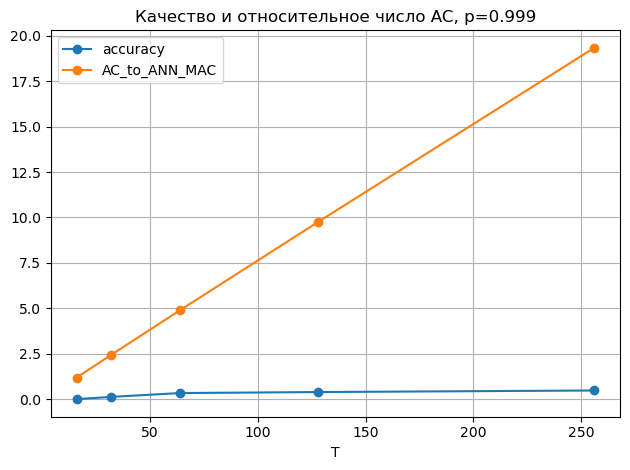

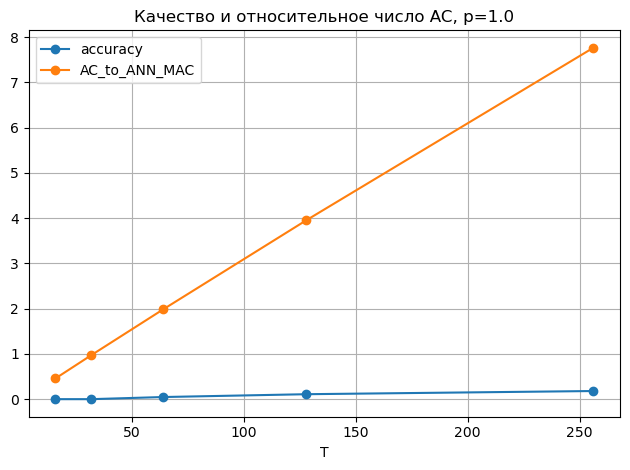

In [16]:
for p, table in all_results.groupby('p'):
    ax = table.plot(
        x='T', y=['accuracy', 'AC_to_ANN_MAC'], marker='o', grid=True,
        title=f'Качество и относительное число AC, p={p}'
    )
    ax.figure.tight_layout()


### 12.1. Эксперимент: перенос MaxPool перед первым IF

Сравниваем текущий спайковый MaxPool с обычным MaxPool над постоянным током первой свёртки. Меняется только место и тип pooling: пороги остаются общими, по одному на слой, начальный потенциал IF — нулевым. Калибровка для обоих вариантов выполняется один раз при p=0.999, на прежних точках ANN. Размер скользящего окна берётся из `MAXPOOL_WINDOW`.

Обычный MaxPool до IF — отдельный гибридный вариант, а не реализация спайкового pooling из пункта 9. Таблица показывает точность на одной и той же тестовой выборке для T=16,32,64,128,256.


In [17]:
torch.manual_seed(SEED)
pool_thresholds = calibrate_thresholds(0.999)
pool_checkpoints = [16, 32, 64, 128, 256]
pool_tables = []

for variant in ('spiking_pool', 'pool_before_IF'):
    pool_model = SpikingResNet18(ann_folded, pool_thresholds).to(device).eval()
    if variant == 'pool_before_IF':
        pool_model.conv1 = nn.Sequential(
            pool_model.conv1, copy.deepcopy(ann_folded.maxpool)
        )
        pool_model.maxpool = nn.Identity()

    table = evaluate_snn_checkpoints(
        pool_model, classification_loader, pool_checkpoints
    )[['T', 'accuracy', 'accuracy_drop']]
    table['variant'] = variant
    table['ANN_accuracy'] = ann_accuracy
    table['p'] = 0.999
    table['window'] = MAXPOOL_WINDOW if variant == 'spiking_pool' else None
    pool_tables.append(table)
    pool_model.op_counter.close()
    del pool_model

pool_comparison = pd.concat(pool_tables, ignore_index=True)
pool_comparison.to_csv(RESULTS_DIR / 'maxpool_comparison.csv', index=False)
pool_comparison


  0%|          | 0/16 [00:00<?, ?it/s]

SNN classification:   0%|          | 0/16 [00:00<?, ?it/s]

SNN classification:   0%|          | 0/16 [00:00<?, ?it/s]

,T,accuracy,accuracy_drop,variant,ANN_accuracy,p,window
0,16,0.007812,0.742188,spiking_pool,0.75,0.999,512
1,32,0.140625,0.609375,spiking_pool,0.75,0.999,512
2,64,0.375000,0.375000,spiking_pool,0.75,0.999,512
3,128,0.414062,0.335938,spiking_pool,0.75,0.999,512
4,256,0.500000,0.250000,spiking_pool,0.75,0.999,512
5,16,0.000000,0.750000,pool_before_IF,0.75,0.999,None
6,32,0.218750,0.531250,pool_before_IF,0.75,0.999,None
7,64,0.570312,0.179688,pool_before_IF,0.75,0.999,None
8,128,0.695312,0.054688,pool_before_IF,0.75,0.999,None
9,256,0.718750,0.031250,pool_before_IF,0.75,0.999,None


## 13. Адаптация под другую задачу: сегментация Oxford-IIIT Pet

Замороженный ANN-энкодер после folding и голова `Conv2d(512, 1)` с увеличением маски до 224×224. Обучается только голова на `trainval`; оценка проводится на отдельном `test`. Граница trimap (метка 3) исключается из loss и метрик.

Одна и та же голова применяется к ANN-признакам и усреднённым по времени SNN-признакам после `layer4`. Пороги SNN калибруются на Imagenette. IoU и Dice для животного усредняются по изображениям. В FAST_MODE используются 256 обучающих и 32 тестовых изображения; скачивается полный датасет. Результаты, веса головы и примеры масок сохраняются в `RESULTS_DIR`.


In [18]:
import matplotlib.pyplot as plt
from torchvision.transforms import InterpolationMode

SEG_SIZE = 224
SEG_EPOCHS = 5
SEG_TRAIN_SAMPLES = 256 if FAST_MODE else None
SEG_TEST_SAMPLES = 32 if FAST_MODE else None

# Одинаковое изменение геометрии изображения и маски, без случайной обрезки.
def pet_transform(image, mask):
    image = TF.resize(image, [SEG_SIZE, SEG_SIZE])
    image = TF.normalize(TF.to_tensor(image),
                         mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    mask = TF.resize(mask, [SEG_SIZE, SEG_SIZE],
                     interpolation=InterpolationMode.NEAREST)
    return image, TF.pil_to_tensor(mask).squeeze(0).long()

seg_train = datasets.OxfordIIITPet(
    DATA_DIR, split='trainval', target_types='segmentation',
    transforms=pet_transform, download=True,
)
seg_test = datasets.OxfordIIITPet(
    DATA_DIR, split='test', target_types='segmentation',
    transforms=pet_transform, download=True,
)

def seg_subset(dataset, count):
    indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))
    return Subset(dataset, indices[:count].tolist()) if count is not None else dataset

seg_train_loader = DataLoader(
    seg_subset(seg_train, SEG_TRAIN_SAMPLES), batch_size=CLASSIFICATION_BATCH_SIZE,
    shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(SEED),
)
seg_test_loader = DataLoader(
    seg_subset(seg_test, SEG_TEST_SAMPLES), batch_size=CLASSIFICATION_BATCH_SIZE,
    shuffle=False, num_workers=0,
)
print('Сегментация: train/test =', len(seg_train_loader.dataset), len(seg_test_loader.dataset))

100%|██████████| 792M/792M [01:08<00:00, 11.5MB/s] 
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.6MB/s]


Сегментация: train/test = 256 32


In [19]:
def ann_features(images):
    x = ann_folded.maxpool(ann_folded.relu(ann_folded.bn1(ann_folded.conv1(images))))
    for layer in (ann_folded.layer1, ann_folded.layer2, ann_folded.layer3, ann_folded.layer4):
        x = layer(x)
    return x


def segmentation_logits(features, size):
    return F.interpolate(seg_head(features), size=size, mode='bilinear',
                         align_corners=False).squeeze(1)


torch.manual_seed(SEED)
seg_head = nn.Conv2d(512, 1, kernel_size=1).to(device)
optimizer = torch.optim.Adam(seg_head.parameters(), lr=1e-3)
ann_folded.eval()
seg_head.train()

for epoch in range(SEG_EPOCHS):
    loss_sum = 0.0
    for images, masks in tqdm(seg_train_loader, desc=f'Голова: эпоха {epoch + 1}'):
        images, masks = images.to(device), masks.to(device)
        with torch.no_grad():
            features = ann_features(images)
        logits = segmentation_logits(features, masks.shape[-2:])
        # Oxford Pet: 1 — животное, 2 — фон, 3 — граница (не учитываем).
        valid = masks != 3
        losses = F.binary_cross_entropy_with_logits(logits, (masks == 1).float(), reduction='none')
        loss = losses[valid].mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * images.shape[0]
    print(f'Loss: {loss_sum / len(seg_train_loader.dataset):.4f}')

seg_head.eval()
torch.save(seg_head.state_dict(), RESULTS_DIR / 'segmentation_head.pt')

Голова: эпоха 1:   0%|          | 0/32 [00:00<?, ?it/s]

Loss: 0.6944


Голова: эпоха 2:   0%|          | 0/32 [00:00<?, ?it/s]

Loss: 0.5068


Голова: эпоха 3:   0%|          | 0/32 [00:00<?, ?it/s]

Loss: 0.4288


Голова: эпоха 4:   0%|          | 0/32 [00:00<?, ?it/s]

Loss: 0.3871


Голова: эпоха 5:   0%|          | 0/32 [00:00<?, ?it/s]

Loss: 0.3597


In [20]:
def segmentation_scores(prediction, masks):
    valid = masks != 3
    prediction = prediction & valid
    target = (masks == 1) & valid
    dims = (1, 2)
    intersection = (prediction & target).sum(dims).float()
    union = (prediction | target).sum(dims).float()
    size = prediction.sum(dims) + target.sum(dims)
    iou = (intersection + 1e-6) / (union + 1e-6)
    dice = (2 * intersection + 1e-6) / (size + 1e-6)
    return iou, dice


def snn_feature_checkpoints(model, images, checkpoints):
    model.reset_state()
    model.op_counter.enabled = False
    current = model.conv1(images)
    feature_sum = 0
    for t in range(1, max(checkpoints) + 1):
        x = model.maxpool(model.if1(current))
        for layer in (model.layer1, model.layer2, model.layer3, model.layer4):
            x = layer(x)
        feature_sum = feature_sum + x
        if t in checkpoints:
            yield t, feature_sum / t


@torch.inference_mode()
def evaluate_segmentation(model=None, checkpoints=(0,)):
    totals = {t: [0.0, 0.0] for t in checkpoints}
    examples = None
    for images, masks in tqdm(seg_test_loader, desc='Сегментация'):
        images, masks = images.to(device), masks.to(device)
        features = ([(0, ann_features(images))] if model is None
                    else snn_feature_checkpoints(model, images, checkpoints))
        for t, batch_features in features:
            prediction = segmentation_logits(batch_features, masks.shape[-2:]) > 0
            iou, dice = segmentation_scores(prediction, masks)
            totals[t][0] += iou.sum().item()
            totals[t][1] += dice.sum().item()
            if examples is None and t == max(checkpoints):
                examples = (images[:3].cpu(), masks[:3].cpu(), prediction[:3].cpu())
    count = len(seg_test_loader.dataset)
    rows = [{'T': t, 'IoU': values[0] / count, 'Dice': values[1] / count}
            for t, values in totals.items()]
    return pd.DataFrame(rows), examples


def save_segmentation_examples(ann_examples, snn_examples, p, t):
    images, masks, ann_predictions = ann_examples
    snn_predictions = snn_examples[2]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    fig, axes = plt.subplots(len(images), 4, figsize=(12, 3 * len(images)), squeeze=False)
    for i in range(len(images)):
        axes[i, 0].imshow((images[i] * std + mean).clamp(0, 1).permute(1, 2, 0))
        # Граница показана серым; при оценке она исключается.
        target = (masks[i] == 1).float()
        target[masks[i] == 3] = 0.5
        for j, mask in enumerate((target, ann_predictions[i], snn_predictions[i]), start=1):
            axes[i, j].imshow(mask, cmap='gray', vmin=0, vmax=1)
        for ax, title in zip(axes[i], ('Изображение', 'Разметка', 'ANN', f'SNN p={p}, T={t}')):
            ax.set_title(title)
            ax.axis('off')
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'segmentation_p{p}.png', dpi=150)
    plt.show()
    plt.close(fig)

Сегментация:   0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

Сегментация:   0%|          | 0/4 [00:00<?, ?it/s]

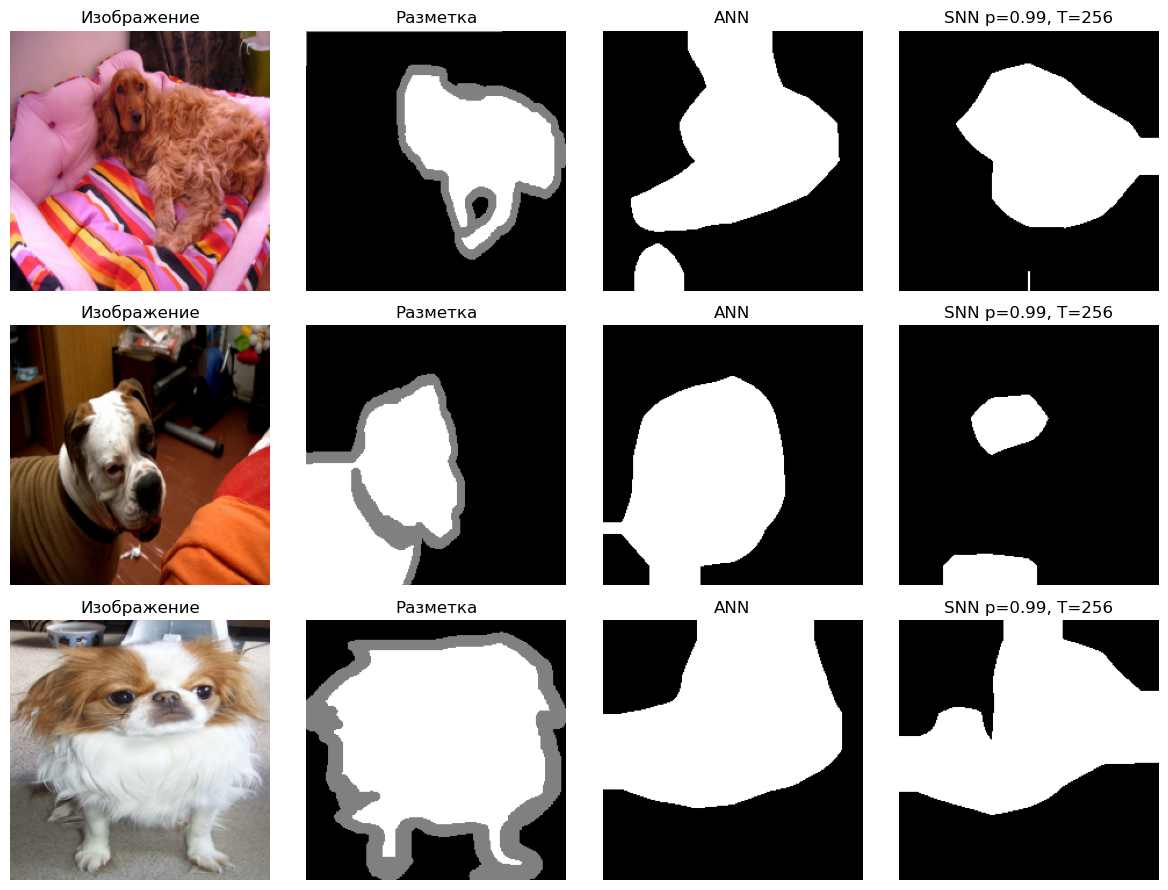

  0%|          | 0/16 [00:00<?, ?it/s]

Сегментация:   0%|          | 0/4 [00:00<?, ?it/s]

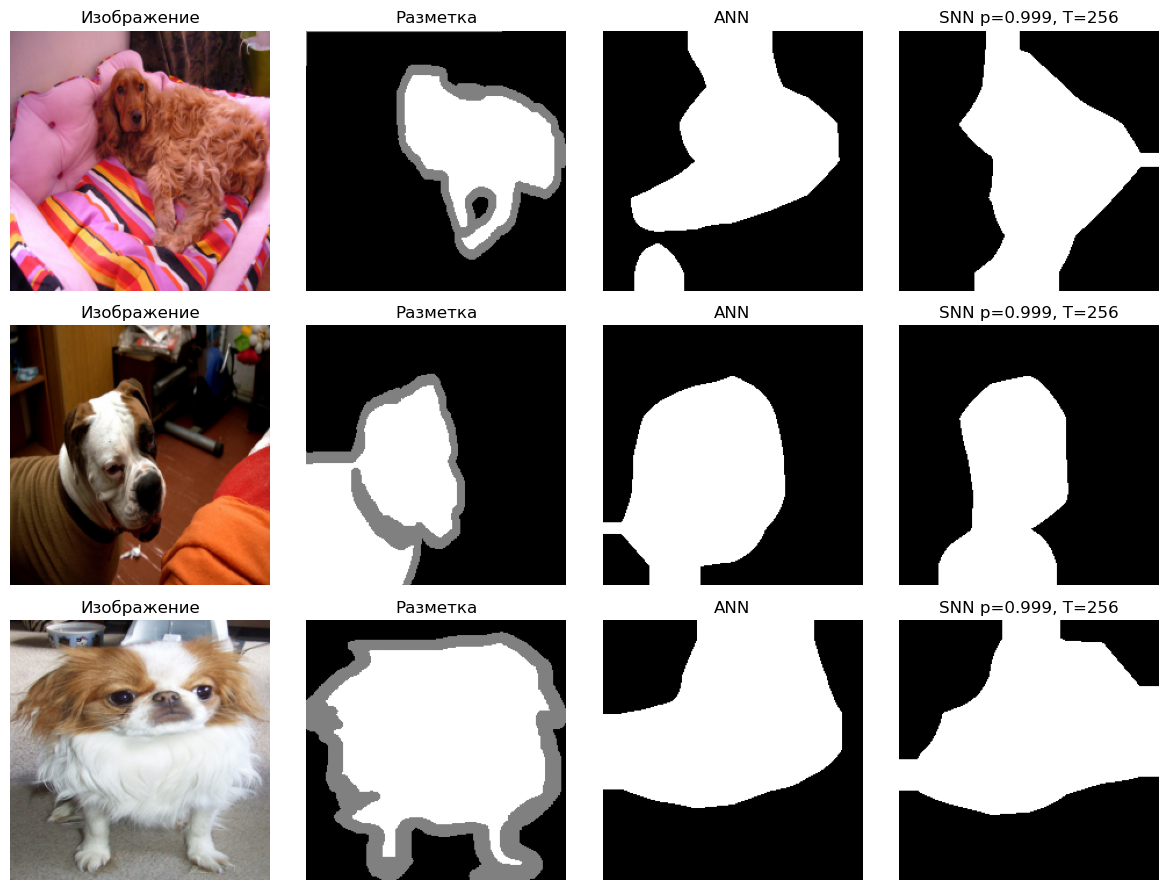

  0%|          | 0/16 [00:00<?, ?it/s]

Сегментация:   0%|          | 0/4 [00:00<?, ?it/s]

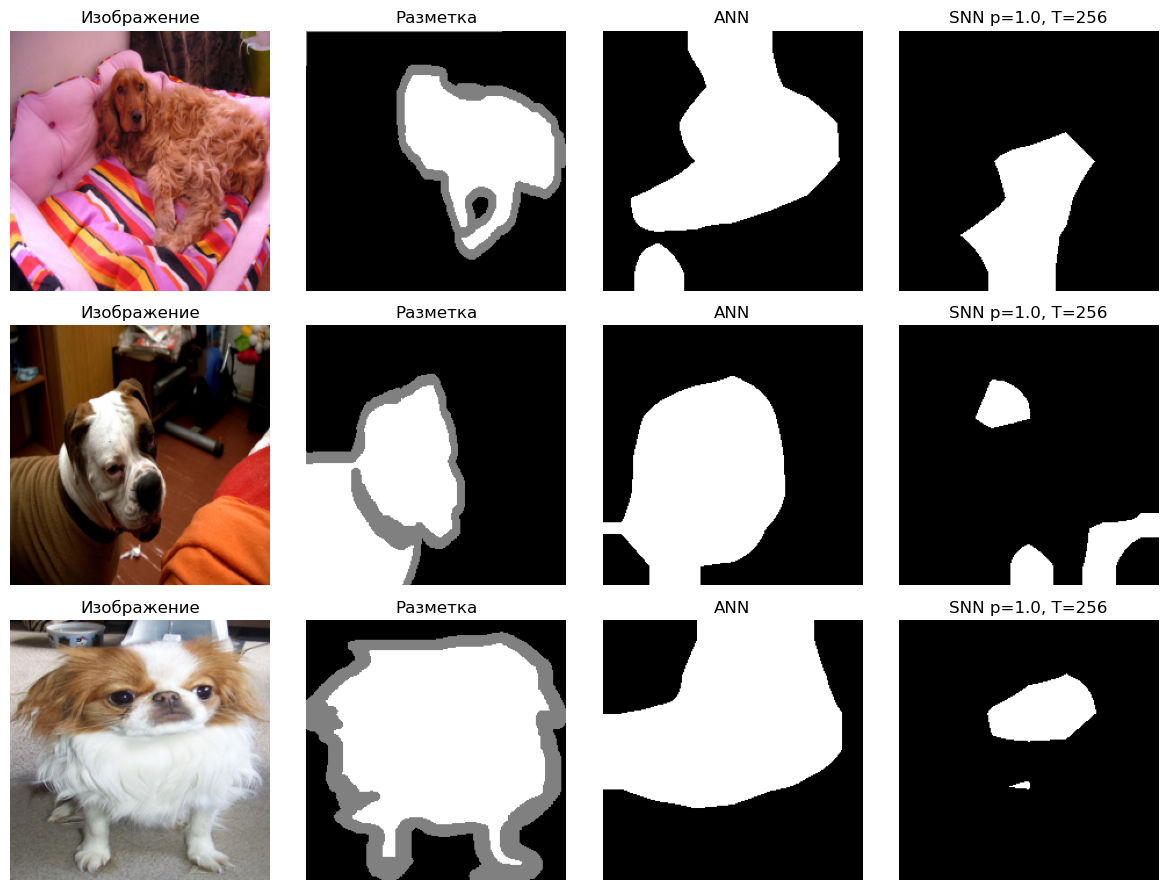

,T,IoU,Dice,model,p
0,0,6.162106e-01,7.503191e-01,ANN,NaN
1,16,5.184221e-02,8.291413e-02,SNN,0.990
2,32,2.488695e-01,3.466499e-01,SNN,0.990
3,64,3.539971e-01,4.744189e-01,SNN,0.990
4,128,4.240736e-01,5.499209e-01,SNN,0.990
5,256,4.827198e-01,6.179115e-01,SNN,0.990
6,16,6.457996e-02,9.994503e-02,SNN,0.999
7,32,2.934440e-01,3.942247e-01,SNN,0.999
8,64,4.110747e-01,5.368061e-01,SNN,0.999
9,128,4.427329e-01,5.748465e-01,SNN,0.999


In [21]:
ann_seg_results, ann_examples = evaluate_segmentation()
ann_seg_results['model'] = 'ANN'
ann_seg_results['p'] = float('nan')
ann_seg_results.to_csv(RESULTS_DIR / 'segmentation_ann.csv', index=False)
seg_tables = [ann_seg_results]

for p in (0.99, 0.999, 1.0):
    # Пороги по Imagenette: тестовые маски Oxford Pet в калибровке не участвуют.
    torch.manual_seed(SEED)
    seg_thresholds = calibrate_thresholds(p)
    seg_snn = SpikingResNet18(ann_folded, seg_thresholds).to(device).eval()
    table, snn_examples = evaluate_segmentation(seg_snn, T_CHECKPOINTS)
    table['model'] = 'SNN'
    table['p'] = p
    seg_tables.append(table)
    table.to_csv(RESULTS_DIR / f'segmentation_p{p}.csv', index=False)
    save_segmentation_examples(ann_examples, snn_examples, p, max(T_CHECKPOINTS))
    seg_snn.op_counter.close()
    del seg_snn

segmentation_results = pd.concat(seg_tables, ignore_index=True)
segmentation_results.to_csv(RESULTS_DIR / 'segmentation_results.csv', index=False)
segmentation_results

## 14. Сводная таблица

При интерпретации результатов необходимо различать:

- **MAC ANN** — умножение с накоплением для плотной сети;
- **AC/SynOps SNN** — прибавление веса при входном событии;
- **residual AC** — сложения двух ветвей residual-блока;
- **spikes** — число событий, а не число синаптических операций;

Один спайк может инициировать много SynOps, поскольку связан со многими нейронами следующего слоя.

## 15. Задания для самостоятельной работы

### Обязательная часть

1. Запустите калибровку с $p\in\{0.99,0.999,1.0\}$ и объясните влияние порога на точность и число спайков.
2. Заполните таблицу для $T=16,32,64,128,256$.
3. Найдите минимальный $T$, при котором падение accuracy относительно ANN не превышает 2 процентных пунктов.
4. Сравните `spikes_per_image` и `total_AC_per_image`. В чём отличие?

### Вопросы к отчёту

- Какие ошибки конверсии уменьшаются при росте $T$?
- Почему BatchNorm необходимо свернуть до конверсии?
- Почему shortcut и основная ветвь должны иметь согласованный масштаб?
- Почему уменьшение числа спайков не гарантирует уменьшение энергии?
- Какие операции этой реализации не вошли в MAC/AC-модель?

## 16. Формат отчёта

Отчёт должен содержать:

1. краткое описание алгоритма конверсии;
2. проверку эквивалентности ANN до и после BatchNorm folding;
3. таблицу accuracy, MAC, AC и числа спайков для всех $T$;
4. график accuracy–$T$ и AC–$T$;
5. таблицу IoU/Dice для задачи сегментации;
6. примеры исходного изображения, разметки, ANN- и SNN-предсказания;
7. обсуждение ограничений принятой модели стоимости;
8. вывод о рекомендуемом $T$.

## 17. Отчёт по лабораторной работе

### Цель и условия эксперимента

Предобученная ResNet18 преобразована в спайковую сеть без переобучения её весов. Проверены классификация фрагмента ImageNet и перенос признаков на сегментацию животных.

| Параметр | Значение |
| --- | --- |
| Исходная модель | ResNet18, предобученная на ImageNet-1k |
| Данные классификации | Локальный архив Imagenette; фактически 7 классов, выход модели — 1000 классов |
| Калибровка / оценка | 128 / 128 разных изображений; случайное разбиение с SEED=42 |
| Пороги | Один на каждое из 17 мест ReLU: p99, p99.9 или максимум |
| Время моделирования | T = 16, 32, 64, 128, 256 тактов |
| Начальный потенциал IF | 0 |
| Окно спайкового MaxPool | W=512 тактов |

Перцентили оценены по подвыборке положительных активаций, максимум — по всем наблюдавшимся активациям калибровки. Поскольку W больше любого проверенного T, в этих экспериментах MaxPool фактически учитывает всю историю текущего изображения: до удаления старых событий дело не доходит.

### Как выполнена конверсия

BatchNorm объединён с предшествующими свёртками, включая downsample-ветви. Выходы до и после folding проверены на одном изображении на CPU в float64: максимальная абсолютная разница **1,27 × 10⁻¹⁴**.

Каждый ReLU заменён IF-нейроном с вычитанием порога после спайка. Выход нейрона равен `порог × спайк`, поэтому сохраняется масштаб исходных признаков. В residual-блоке складываются основная и обходная ветви, затем применяется второй IF. У двух IF внутри блока отдельные состояния и пороги.

Первая свёртка вычисляется один раз, её постоянный ток подаётся на первый IF каждый такт. Спайковый MaxPool выбирает вход по числу событий в окне и пропускает его текущий спайк. Выходные логиты усредняются по T тактам. Перед каждым батчем состояния сбрасываются.

### Классификация и стоимость вычислений

Исходная ANN: **75% accuracy (96 из 128)**, **1,814 млрд MAC** и **0,753 млн residual AC** на изображение. Ниже MAC, AC и спайки также приведены на одно изображение. AC — оценка по принятой в коде модели, а не измерение операций GPU.


| Порог | T | Accuracy, % | MAC, млрд | AC, млрд | Спайки, млн | Спайки/нейрон |
| --- | --- | --- | --- | --- | --- | --- |
| p99 | 16 | 0.00 | 0.126 | 3.138 | 5.98 | 2.59 |
| p99 | 32 | 16.41 | 0.134 | 6.363 | 12.20 | 5.28 |
| p99 | 64 | 31.25 | 0.151 | 12.793 | 24.65 | 10.68 |
| p99 | 128 | 36.72 | 0.184 | 25.612 | 49.61 | 21.49 |
| p99 | 256 | 43.75 | 0.249 | 51.238 | 99.70 | 43.20 |
| p99.9 | 16 | 0.78 | 0.126 | 2.168 | 3.95 | 1.71 |
| p99.9 | 32 | 13.28 | 0.134 | 4.425 | 8.13 | 3.52 |
| p99.9 | 64 | 34.38 | 0.151 | 8.894 | 16.48 | 7.14 |
| p99.9 | 128 | 39.84 | 0.184 | 17.696 | 33.08 | 14.33 |
| p99.9 | 256 | 48.44 | 0.249 | 35.059 | 66.14 | 28.66 |
| max | 16 | 0.00 | 0.126 | 0.831 | 1.29 | 0.56 |
| max | 32 | 0.00 | 0.134 | 1.764 | 2.84 | 1.23 |
| max | 64 | 4.69 | 0.151 | 3.595 | 5.92 | 2.56 |
| max | 128 | 10.94 | 0.184 | 7.172 | 12.02 | 5.21 |
| max | 256 | 17.97 | 0.249 | 14.078 | 24.02 | 10.40 |


Лучший основной результат — **48,44% при p99.9 и T=256**. Потеря относительно ANN — **26,56 п.п.** Увеличение T улучшает точность, но почти пропорционально увеличивает число событий и AC. При p99 спайков больше, чем при p99.9, однако точность ниже: увеличение активности само по себе не гарантирует качество. Max-порог даёт самые редкие спайки и худшую точность на всех проверенных T.

Для падения не более 2 п.п. нужна accuracy не ниже 73%, то есть минимум 94 правильных ответа из 128 (73,44%). **В основном эксперименте подходящего T не найдено ни для одного порога.** Графики зависимости accuracy и относительного числа AC от T приведены в секции 12.

### Распределение спайков по слоям

Для лучшего основного режима, p99.9 и T=256. Значения усреднены по тестовым изображениям; спайки на нейрон посчитаны за все 256 тактов, без дополнительного деления на T.


| IF-узел | Спайки/изображение, млн | Спайки/нейрон |
| --- | --- | --- |
| relu | 28.364 | 35.33 |
| layer1.0.relu1 | 4.822 | 24.03 |
| layer1.0.relu2 | 9.458 | 47.13 |
| layer1.1.relu1 | 3.787 | 18.87 |
| layer1.1.relu2 | 9.192 | 45.80 |
| layer2.0.relu1 | 2.114 | 21.07 |
| layer2.0.relu2 | 2.359 | 23.50 |
| layer2.1.relu1 | 0.857 | 8.54 |
| layer2.1.relu2 | 1.931 | 19.24 |
| layer3.0.relu1 | 0.521 | 10.39 |
| layer3.0.relu2 | 0.792 | 15.78 |
| layer3.1.relu1 | 0.268 | 5.35 |
| layer3.1.relu2 | 0.777 | 15.48 |
| layer4.0.relu1 | 0.130 | 5.17 |
| layer4.0.relu2 | 0.158 | 6.30 |
| layer4.1.relu1 | 0.175 | 6.98 |
| layer4.1.relu2 | 0.439 | 17.51 |


Основная доля событий приходится на входной слой и первые residual-блоки. Число спайков и число AC различаются: один спайк может передаваться множеству выходных нейронов и вызывать много прибавлений весов. Для этого режима получено **66,14 млн спайков** и **35,06 млрд оценочных AC** на изображение.

### Дополнительный эксперимент: MaxPool перед первым IF

Заменён только pooling: обычный MaxPool применяется к постоянному току первой свёртки до IF. Пороги по-прежнему скалярные на слой, начальный потенциал нулевой. Оба варианта используют один общий набор порогов p99.9 и одну тестовую выборку.


| T | Спайковый MaxPool, % | MaxPool перед IF, % |
| --- | --- | --- |
| 16 | 0.78 | 0.00 |
| 32 | 14.06 | 21.88 |
| 64 | 37.50 | 57.03 |
| 128 | 41.41 | 69.53 |
| 256 | 50.00 | 71.88 |


При T=256 перенос MaxPool повышает accuracy **с 50,00% до 71,88%** в этом парном сравнении. Это указывает на существенный вклад оценки максимума по спайкам в потерю качества. Гибридный вариант не выполняет спайковый pooling из пункта 9, поэтому его результат приведён отдельно. Падение относительно ANN составляет 3,12 п.п.; условие ≤2 п.п. здесь также не достигнуто.

Контрольные 50,00% отличаются от основных 48,44% из-за отдельной калибровки со случайной подвыборкой активаций. Внутри дополнительного эксперимента пороги у двух моделей одинаковы.

### Перенос на сегментацию Oxford-IIIT Pet

Обучена голова `Conv2d(512, 1)` на замороженных признаках ANN после layer4. Маска увеличивается с 7×7 до 224×224. Обучение: 256 изображений trainval, 5 эпох, Adam с lr=0.001. Loss снизился с 0,6944 до 0,3597. Оценка проведена на 32 изображениях отдельного test-разбиения.

Для SNN использована та же голова с усреднёнными по времени признаками; веса головы не дообучались. Пороги заново калибровались на Imagenette, без тестовых масок Oxford Pet. Из-за случайной выборки активаций они не обязаны точно совпадать с порогами классификационного прогона. Граница trimap исключена из loss и метрик. IoU и Dice рассчитаны для животного и усреднены по изображениям.

ANN: **IoU=0,616; Dice=0,750**. В ячейках таблицы — **IoU / Dice** для SNN.


| T | p99 | p99.9 | max |
| --- | --- | --- | --- |
| 16 | 0.052 / 0.083 | 0.065 / 0.100 | 0.000 / 0.000 |
| 32 | 0.249 / 0.347 | 0.293 / 0.394 | 0.000 / 0.001 |
| 64 | 0.354 / 0.474 | 0.411 / 0.537 | 0.127 / 0.183 |
| 128 | 0.424 / 0.550 | 0.443 / 0.575 | 0.182 / 0.251 |
| 256 | 0.483 / 0.618 | 0.498 / 0.635 | 0.208 / 0.286 |


Лучший SNN-результат: **IoU=0,498; Dice=0,635**, p99.9, T=256. Отставание от ANN составляет 0,118 по IoU и 0,115 по Dice. Признаки переносятся на новую задачу, но конверсия снижает качество. Простая голова на карте 7×7 также ограничивает точность границ.

Примеры для p99.9, T=256: изображение, разметка, ANN, SNN. Серая полоса в разметке не учитывается в метриках.

![Сравнение масок ANN и SNN](results/segmentation_p0.999.png)

### Интерпретация и ограничения

- **Что улучшает рост T.** Уменьшается ошибка представления активаций конечным числом спайков; у глубоких слоёв появляется больше времени накопить сигнал. Рост T не устраняет насыщение при слишком низких порогах и не гарантирует точную работу MaxPool.
- **Зачем folding.** Он сохраняет преобразование BatchNorm внутри весов и смещений свёртки. После этого калибровка относится к той сети, которая действительно конвертируется.
- **Почему важен масштаб ветвей.** Сложение residual-ветвей должно соответствовать исходному `F(x)+x`. Выход `threshold × spike` сохраняет единицы активаций; несогласованные масштабы изменили бы относительный вклад ветвей.
- **Что означает стоимость.** MAC считаются для аналоговых свёрток/Linear; синаптические AC SNN оценены как стоимость плотного слоя, умноженная на долю ненулевых входов. Это приближение не учитывает точное положение события у границы карты.
- **Residual AC требуют отдельной оговорки.** Для ANN учитывается одно сложение на элемент выхода блока. Для SNN считаются ненулевые элементы обеих ветвей. Это разные модели подсчёта; их столбцы нельзя трактовать как строго сопоставимые количества одинаковых операций.
- **Что не учтено.** Прибавление bias, обновления потенциалов, сравнения, история и выбор MaxPool, AvgPool, накопление логитов, память и передача данных. Меньшее число спайков не доказывает экономию энергии: она зависит от аппаратуры, связности и этих дополнительных затрат. PyTorch здесь выполняет плотные свёртки.
- **Границы выводов.** Использованы небольшие подвыборки: 128 изображений для классификации и 32 для сегментации. Один правильный ответ меняет accuracy на 0,78125 п.п. Окно W=512 при T≤256 не проверяет поведение после вытеснения старых событий.

### Вывод

Реализованы folding, IF с soft reset, residual-блоки и MaxPool с конечным временным окном. Выполнены все 15 комбинаций порога и T, оценены точность, операции и спайки, проверен перенос на сегментацию.

Среди проверенных основных режимов для качества выбран **p99.9, T=256**: accuracy 48,44%, IoU 0,498 и Dice 0,635. Это лучший измеренный режим данной реализации, но он не удовлетворяет ограничению потери классификационной точности ≤2 п.п. Дополнительный вариант с аналоговым MaxPool перед IF достигает 71,88% и показывает, что pooling — существенный источник ошибки. Утверждать сохранение качества ANN или выигрыш в энергии по этим результатам нельзя.

Исходные численные результаты: [классификация](results/all_thresholds_results.csv), [сравнение MaxPool](results/maxpool_comparison.csv), [сегментация](results/segmentation_results.csv). Таблицы отчёта фиксируют текущий завершённый прогон; после новых экспериментов их нужно обновить.
